![logo](https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/images/notebook-logo.png)

## **Curso**: Residência em Inteligência Artificial
## **Unidade Curricular**: Séries Temporais
## **Professor**: Matheus Vanzan
---

### Setup

* `numpy` (`np`): cálculos numéricos
* `pandas` (`pd`): tabelas (`DataFrame`) e séries (`Series`)
* `matplotlib.pyplot` (`plt`): gráficos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

`PATH` é o endereço base dos dados (um repositório no GitHub). Em cada leitura, somamos a ele o caminho do arquivo.

In [ ]:
PATH = 'https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/'

## 📌 1 - Índice de tempo

> **Dataset:** o **AirPassengers** é um dataset clássico (Box & Jenkins): número de passageiros internacionais de uma companhia aérea, **mês a mês**, de 1949 a 1960. Ele mostra, em uma única série, os componentes que vimos nos slides.

O que diferencia uma série temporal de uma tabela comum é o **índice**: cada linha tem um instante de tempo, e a ordem importa.

No pandas, usamos um `DatetimeIndex`. Antes de ler, vamos olhar o **início do arquivo CSV**:

```
"Month","Passengers"
"1949-01",112
"1949-02",118
"1949-03",132
"1949-04",129
"1949-05",121
```

É um arquivo de texto com **duas colunas** separadas por vírgula: `Month` (o mês de cada medida, em texto como `1949-01`) e `Passengers` (o número de passageiros). A primeira linha é o cabeçalho.

Lendo **sem nenhum argumento**, o pandas trata `Month` como texto comum. O método `.head()` mostra as primeiras linhas (por padrão 5; `.head(10)` mostraria 10):

In [ ]:
dados_brutos = pd.read_csv(PATH + 'datasets/air_passengers.csv')
dados_brutos.head()

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


O atributo `.dtypes` informa o **tipo** de cada coluna. O tipo `object` é texto; `int64` é número inteiro:

In [ ]:
print('Tipo da coluna Month:', dados_brutos['Month'].dtype)
print('Tipo da coluna Passengers:', dados_brutos['Passengers'].dtype)

Tipo da coluna Month: object
Tipo da coluna Passengers: int64


`Month` é `object` (texto), e o índice é só 0, 1, 2... Para transformá-la em índice de tempo, usamos argumentos do `pd.read_csv`.

Abaixo estão os principais, um por linha. Os que não precisamos estão com o **valor padrão**. Três mudam o resultado:

* `names` renomeia as colunas para português (`Mes` e `Passageiros`), substituindo o cabeçalho do arquivo (por isso `header=0`)
* `parse_dates` converte `Mes` de texto para data: `'1949-01'` vira a data `1949-01-01` (o pandas completa o dia com 1)
* `index_col` transforma `Mes` em índice

In [ ]:
df_air = pd.read_csv(
    PATH + 'datasets/air_passengers.csv',

    # separador das colunas (padrão ',')
    sep=',',

    # linha com os nomes das colunas (0 = primeira linha; None se o arquivo não tem cabeçalho)
    header=0,

    # nomes das colunas: aqui trocamos os nomes do arquivo por português
    # (com header=0, substitui o cabeçalho; sem cabeçalho, apenas dá os nomes)
    names=['Mes', 'Passageiros'],

    # lê só algumas colunas (ex.: ['Passageiros'])
    usecols=None,

    # força o tipo de cada coluna (ex.: {'Passageiros': 'float'})
    dtype=None,

    # textos que devem virar valor ausente (ex.: ['-', 'N/A'])
    na_values=None,

    # lê só as primeiras N linhas (ex.: 24)
    nrows=None,

    # colunas a converter de texto para datas
    parse_dates=['Mes'],

    # coluna que vira o índice
    index_col='Mes',
)

In [ ]:
df_air.head()

,Passageiros
Mes,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


O atributo `.index` devolve o índice da tabela. Quando o tipo é `DatetimeIndex`, o pandas entende cada linha como um **instante de tempo**:

In [ ]:
df_air.index

DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01', '1949-04-01',
               '1949-05-01', '1949-06-01', '1949-07-01', '1949-08-01',
               '1949-09-01', '1949-10-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[ns]', name='Mes', length=144, freq=None)

In [ ]:
print('Tipo do índice:', type(df_air.index).__name__)
print('Nome do índice:', df_air.index.name)

Tipo do índice: DatetimeIndex
Nome do índice: Mes


Uma análise rápida do índice. A **primeira data** é o menor valor do índice, `.min()`. O `.date()` mostra só a data, sem a hora:

In [ ]:
print('Primeira data:', df_air.index.min().date())

Primeira data: 1949-01-01


A **última data** é o maior valor, `.max()`:

In [ ]:
print('Última data:', df_air.index.max().date())

Última data: 1960-12-01


`len()` conta as linhas:

In [ ]:
print('Número de linhas:', len(df_air))

Número de linhas: 144


`.day` extrai o dia de cada data, e `.unique()` lista os valores sem repetição:

In [ ]:
print('Dias do mês presentes:', list(df_air.index.day.unique()))

Dias do mês presentes: [1]


São **144 linhas** (12 anos x 12 meses) e todas no **dia 1**: a série tem **uma medida por mês**, não tem dados diários. O dia 1 é só o jeito do pandas representar "o mês inteiro" como uma data.

Com o índice de datas, selecionamos linhas pelo **rótulo** com o `.loc` (o rótulo de cada linha é a data, não a posição). Começando só pelo ano, como texto:

In [ ]:
ano_1950 = df_air.loc['1950']
ano_1950

,Passageiros
Mes,
1950-01-01,115
1950-02-01,126
1950-03-01,141
1950-04-01,135
1950-05-01,125
1950-06-01,149
1950-07-01,170
1950-08-01,170
1950-09-01,158


In [ ]:
print('Linhas selecionadas:', len(ano_1950))
print('Primeira linha:', ano_1950.index[0].date())
print('Última linha:', ano_1950.index[-1].date())

Linhas selecionadas: 12
Primeira linha: 1950-01-01
Última linha: 1950-12-01


> Nos prints, `.index[0]` é o primeiro rótulo do resultado e `.index[-1]` é o último.

Veio o ano todo, os 12 meses de 1950. Agora com ano e mês:

In [ ]:
mes_1950_06 = df_air.loc['1950-06']
mes_1950_06

,Passageiros
Mes,
1950-06-01,149


In [ ]:
print('Linhas selecionadas:', len(mes_1950_06))
print('Primeira linha:', mes_1950_06.index[0].date())
print('Última linha:', mes_1950_06.index[-1].date())

Linhas selecionadas: 1
Primeira linha: 1950-06-01
Última linha: 1950-06-01


Veio só junho de 1950 (uma linha), ainda como tabela. Agora com o dia completo:

In [ ]:
dia_1950_06_01 = df_air.loc['1950-06-01']
dia_1950_06_01

,1950-06-01
Passageiros,149


In [ ]:
print('Tipo do resultado:', type(dia_1950_06_01).__name__)
print('Rótulo da linha:', dia_1950_06_01.name.date())
print('Passageiros:', dia_1950_06_01['Passageiros'])

Tipo do resultado: Series
Rótulo da linha: 1950-06-01
Passageiros: 149


Com o dia completo deixou de ser tabela e virou uma única linha (uma `Series`). E se o dia pedido não existe no índice? Como a série é mensal, só existem os dias 1:

In [ ]:
try:
    df_air.loc['1950-06-15']
except KeyError as erro:
    print('KeyError: o rótulo', erro, 'não existe no índice')

KeyError: o rótulo '1950-06-15' não existe no índice


Com **dois rótulos**, `.loc[inicio:fim]` seleciona o intervalo. Diferente do fatiamento de listas do Python, o **fim é incluído**:

In [ ]:
intervalo = df_air.loc['1950-06':'1951-02']
intervalo

,Passageiros
Mes,
1950-06-01,149
1950-07-01,170
1950-08-01,170
1950-09-01,158
1950-10-01,133
1950-11-01,114
1950-12-01,140
1951-01-01,145
1951-02-01,150


In [ ]:
print('Linhas selecionadas:', len(intervalo))
print('Primeira linha:', intervalo.index[0].date())
print('Última linha:', intervalo.index[-1].date())

Linhas selecionadas: 9
Primeira linha: 1950-06-01
Última linha: 1951-02-01


Como `'1951-02'` é um período, entrou o mês inteiro de fevereiro de 1951.

**Por que funciona assim:** o pandas converte o texto em data e compara a **precisão** do texto com a precisão do índice (aqui, o **dia**):

1. Texto **menos preciso** que o índice: vira um **período**, e devolve todas as linhas dentro dele
2. Texto **tão preciso** quanto o índice: vira uma **busca exata**, e devolve só aquela linha

| Texto | Precisão | O que seleciona |
|---|---|---|
| `'1950'` | ano | todas as linhas de 1950 (12 meses) |
| `'1950-06'` | mês | todas as linhas de junho de 1950 (1 linha) |
| `'1950-06-01'` | dia | a linha exata do dia 1950-06-01 |

> O texto precisa começar com o **ano de 4 dígitos**, seguido de mês e dia nessa ordem. Textos como `'50'` ou `'06'` não são reconhecidos como data.

Para analisar a série, selecionamos a coluna `Passageiros`. Com **um nome entre colchetes**, `df_air['Passageiros']` devolve uma `Series`: um vetor de valores que mantém o índice de datas.

In [ ]:
passageiros = df_air['Passageiros']
passageiros.head()

,Passageiros
Mes,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [ ]:
print('Tipo:', type(passageiros).__name__)
print('Nome:', passageiros.name)
print('Tamanho:', len(passageiros))

Tipo: Series
Nome: Passageiros
Tamanho: 144


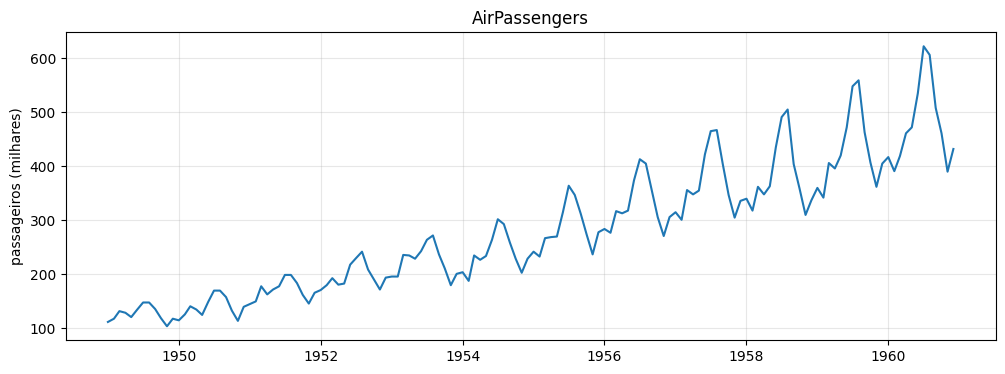

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(passageiros.index, passageiros.values)
plt.title('AirPassengers')
plt.ylabel('passageiros (milhares)')
plt.grid(alpha=0.3)
plt.show()

No gráfico vemos:

* **Tendência:** o número de passageiros cresce ao longo dos anos
* **Sazonalidade:** o padrão se repete a cada 12 meses
* A **amplitude** da oscilação também cresce com o tempo

## 📌 2 - Dependência temporal

Em dados tabulares, em geral **assumimos** que as linhas são independentes umas das outras: embaralhar as linhas não muda nada. Em uma série temporal, o valor de agora depende do passado. Vamos verificar isso na série `passageiros`.

### 2.1 - A ordem importa

Vamos **embaralhar** a série: os valores são os mesmos, só a ordem muda. O `np.random.default_rng(42)` cria um gerador de números aleatórios (a semente 42 faz o resultado ser sempre o mesmo), e o método `.permutation()` embaralha os valores. O `index=passageiros.index` mantém as datas originais:

In [ ]:
rng = np.random.default_rng(42)
embaralhada = pd.Series(rng.permutation(passageiros.values), index=passageiros.index)
embaralhada.head()

,0
Mes,
1949-01-01,158
1949-02-01,237
1949-03-01,129
1949-04-01,559
1949-05-01,364


A média e o desvio-padrão (`.std()`) são os mesmos nas duas séries:

In [ ]:
print('Média | original:', round(passageiros.mean(), 2), '| embaralhada:', round(embaralhada.mean(), 2))
print('Desvio-padrão | original:', round(passageiros.std(), 2), '| embaralhada:', round(embaralhada.std(), 2))

Média | original: 280.3 | embaralhada: 280.3
Desvio-padrão | original: 119.97 | embaralhada: 119.97


Mas o gráfico mostra a diferença:

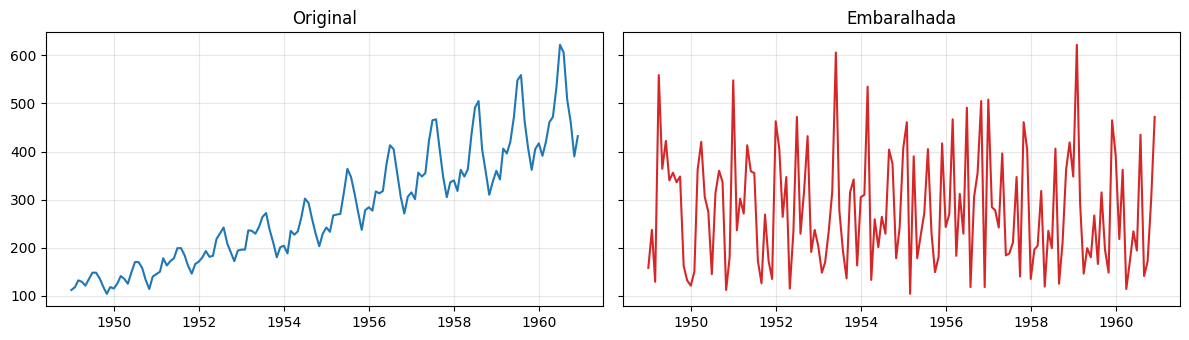

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
eixos[0].plot(passageiros.index, passageiros.values)
eixos[0].set_title('Original')
eixos[1].plot(embaralhada.index, embaralhada.values, color='tab:red')
eixos[1].set_title('Embaralhada')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Mesma média e mesmo desvio-padrão, mas a informação estava na **ordem**: a tendência e a sazonalidade desapareceram.

### 2.2 - Valor atual x valor anterior

Para medir essa dependência, comparamos cada valor com o **anterior**. O método `.shift(1)` desloca a série uma posição: cada linha passa a ter o valor do instante anterior (a primeira fica `NaN`, porque não tem anterior):

In [ ]:
pares = pd.DataFrame({'anterior': passageiros.shift(1), 'atual': passageiros})
pares.head()

,anterior,atual
Mes,,
1949-01-01,NaN,112
1949-02-01,112.0,118
1949-03-01,118.0,132
1949-04-01,132.0,129
1949-05-01,129.0,121


Em um gráfico de dispersão, cada ponto é um par: o valor anterior no eixo horizontal e o valor atual no vertical. Na série original e na embaralhada:

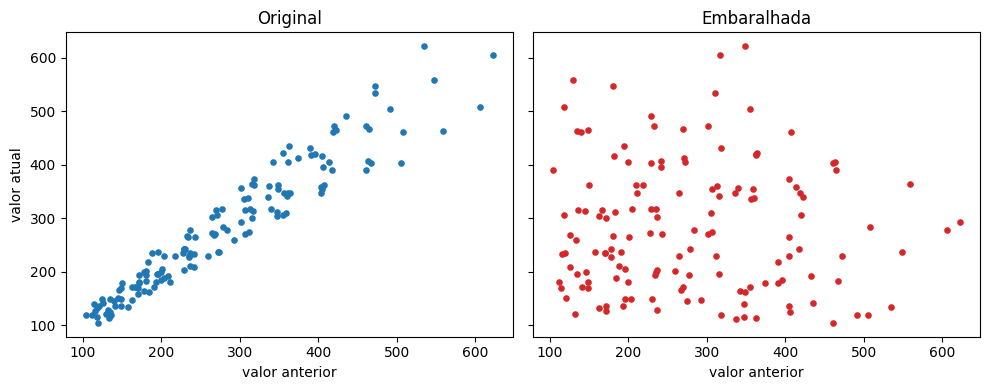

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
eixos[0].scatter(passageiros.shift(1), passageiros, s=14)
eixos[0].set_title('Original')
eixos[1].scatter(embaralhada.shift(1), embaralhada, s=14, color='tab:red')
eixos[1].set_title('Embaralhada')
for eixo in eixos:
    eixo.set_xlabel('valor anterior')
eixos[0].set_ylabel('valor atual')
plt.tight_layout()
plt.show()

Na série original, o valor de agora **se parece com o passado**: os pontos seguem uma diagonal. Na embaralhada, a direção desaparece.

O método `.corr()` mede esse alinhamento em um número, de -1 a 1 (quanto mais perto de 1, mais os pontos seguem uma reta):

In [ ]:
print('Correlação entre valor atual e anterior | original:', round(passageiros.corr(passageiros.shift(1)), 2))
print('Correlação entre valor atual e anterior | embaralhada:', round(embaralhada.corr(embaralhada.shift(1)), 2))

Correlação entre valor atual e anterior | original: 0.96
Correlação entre valor atual e anterior | embaralhada: -0.04


## 📌 3 - Tendência

**Tendência** é a direção de longo prazo da série: sobe, desce ou fica estável. No gráfico, ela aparece misturada com a oscilação que se repete todo ano.

Para isolar a tendência, vamos **resumir cada ano em um único número**: a média dos 12 meses. Dentro de um ano, os meses altos e baixos se compensam e sobra só o **nível** do ano. Começando **na mão**, com os 12 meses de 1949:

In [ ]:
passageiros.loc['1949']

,Passageiros
Mes,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
1949-06-01,135
1949-07-01,148
1949-08-01,148
1949-09-01,136


O método `.mean()` soma os valores e divide pela quantidade. Em uma lista pequena:

In [ ]:
lista = pd.Series([10, 20, 30])
print('Valores:', list(lista))
print('Soma:', lista.sum())
print('Quantidade:', len(lista))
print('Soma / quantidade:', lista.sum() / len(lista))
print('.mean():', lista.mean())

Valores: [10, 20, 30]
Soma: 60
Quantidade: 3
Soma / quantidade: 20.0
.mean(): 20.0


A média dos 12 valores de 1949 é o nível de 1949:

In [ ]:
media_1949 = passageiros.loc['1949'].mean()
print('Média de 1949:', round(media_1949, 2))

Média de 1949: 126.67


E a de 1950:

In [ ]:
media_1950 = passageiros.loc['1950'].mean()
print('Média de 1950:', round(media_1950, 2))

Média de 1950: 139.67


O nível subiu de 1949 para 1950. Para **todos os anos de uma vez**, usamos o `resample`, que muda a **frequência** da série (aqui, de mensal para anual). Primeiro só com o argumento `'YS'`:

In [ ]:
passageiros.resample('YS')

> **O que é `'YS'`:** o código da nova frequência. `Y` é *year* (ano) e `S` é *start* (início): cada grupo é identificado pela data de **início do ano**, como `1949-01-01`. Outros códigos: `'MS'` (mês) e `'QS'` (trimestre).

O resultado é um objeto `Resampler`: ele só **agrupou** as linhas por ano, sem calcular nada. Para ver os grupos, percorremos o objeto com um `for`: cada passo devolve a data de início e as linhas do grupo. Os dois primeiros:

In [ ]:
for inicio, grupo in list(passageiros.resample('YS'))[:2]:
    print('Grupo', inicio.date(), 'com', len(grupo), 'linhas:')
    print([int(v) for v in grupo.values])

Grupo 1949-01-01 com 12 linhas:
[112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118]
Grupo 1950-01-01 com 12 linhas:
[115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140]


O método `.size()` conta as linhas de cada grupo, e `.iloc[0]` e `.iloc[-1]` pegam o primeiro e o último valor **pela posição** (diferente do `.loc`, que usa o rótulo):

In [ ]:
tamanhos = passageiros.resample('YS').size()
print('Número de grupos:', len(tamanhos))
print('Primeiro grupo:', tamanhos.index[0].date(), 'com', tamanhos.iloc[0], 'linhas')
print('Último grupo:', tamanhos.index[-1].date(), 'com', tamanhos.iloc[-1], 'linhas')
print('Linhas por grupo (valores diferentes):', [int(n) for n in tamanhos.unique()])

Número de grupos: 12
Primeiro grupo: 1949-01-01 com 12 linhas
Último grupo: 1960-01-01 com 12 linhas
Linhas por grupo (valores diferentes): [12]


Cada ano tem **12 linhas**, os 12 meses que olhamos na mão. Agora a média de cada grupo, com `.mean()`:

In [ ]:
anual = passageiros.resample('YS').mean()
anual

,Passageiros
Mes,
1949-01-01,126.666667
1950-01-01,139.666667
1951-01-01,170.166667
1952-01-01,197.000000
1953-01-01,225.000000
1954-01-01,238.916667
1955-01-01,284.000000
1956-01-01,328.250000
1957-01-01,368.416667


Conferindo com a conta na mão:

In [ ]:
print('Média de 1949 na mão:', round(media_1949, 2), '| no resample:', round(anual.iloc[0], 2))
print('Média de 1950 na mão:', round(media_1950, 2), '| no resample:', round(anual.iloc[1], 2))

Média de 1949 na mão: 126.67 | no resample: 126.67
Média de 1950 na mão: 139.67 | no resample: 139.67


In [ ]:
print('Linhas antes (mensal):', len(passageiros))
print('Linhas depois (anual):', len(anual))

Linhas antes (mensal): 144
Linhas depois (anual): 12


Para comparar o **antes** e o **depois**, plotamos a série mensal e a média anual no mesmo gráfico. As linhas vermelhas tracejadas separam os anos, e cada bolinha fica no **meio do ano** que ela resume (`anual.index` é o início de cada ano, então somamos 6 meses):

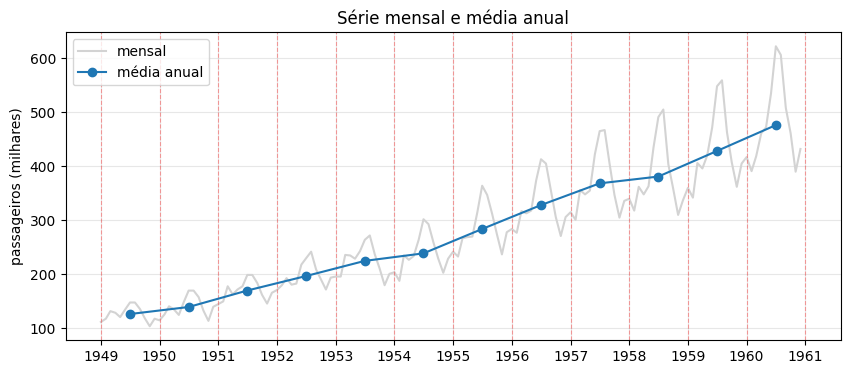

In [ ]:
meio_do_ano = anual.index + pd.DateOffset(months=6)
limites = list(anual.index) + [anual.index[-1] + pd.DateOffset(years=1)]

plt.figure(figsize=(10, 4))
plt.plot(passageiros.index, passageiros.values, color='lightgray', label='mensal')
for limite in limites:
    plt.axvline(limite, color='red', linestyle='--', linewidth=0.8, alpha=0.35)
plt.plot(meio_do_ano, anual.values, marker='o', label='média anual')
plt.xticks(limites, [limite.year for limite in limites])
plt.title('Série mensal e média anual')
plt.ylabel('passageiros (milhares)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A linha da média anual não tem a oscilação: só **sobe**, ano após ano. Essa é a **tendência** do AirPassengers.

## 📌 4 - Sazonalidade

**Sazonalidade** é um padrão que se repete em intervalos fixos. Aqui, o intervalo é de 12 meses: todo ano os mesmos meses são altos e os mesmos são baixos.

Para isolar a sazonalidade, em vez de resumir **cada ano**, resumimos **cada mês do calendário**: a média de todos os janeiros, de todos os fevereiros, e assim por diante.

Retomando a série `passageiros` (a coluna `Passageiros` do `df_air`, criada no início da aula):

In [ ]:
passageiros.head()

,Passageiros
Mes,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


Para isso usamos o `groupby`, que agrupa as linhas pelo valor de uma **chave**. A chave aqui é o mês de cada data: o atributo `.month` extrai o mês (de 1 a 12) do índice. Primeiro só o agrupamento:

In [ ]:
grupos_mes = passageiros.groupby(passageiros.index.month)
grupos_mes

> A diferença para o `resample` é que o `groupby` agrupa por **qualquer chave**, não só por intervalo de tempo.

Como no `resample`, ele só agrupou. Cada grupo reúne as linhas de um mês do calendário, uma por ano. O primeiro grupo (janeiro):

In [ ]:
for mes, grupo in list(grupos_mes)[:1]:
    print('Grupo do mês', mes, 'com', len(grupo), 'linhas:')
    print([int(v) for v in grupo.values])

Grupo do mês 1 com 12 linhas:
[112, 115, 145, 171, 196, 204, 242, 284, 315, 340, 360, 417]


Agora a média de cada grupo, com `.mean()`:

In [ ]:
por_mes = grupos_mes.mean()
por_mes

,Passageiros
Mes,
1,241.750000
2,235.000000
3,270.166667
4,267.083333
5,271.833333
6,311.666667
7,351.333333
8,351.083333
9,302.416667


Para ver o padrão, um gráfico de barras:

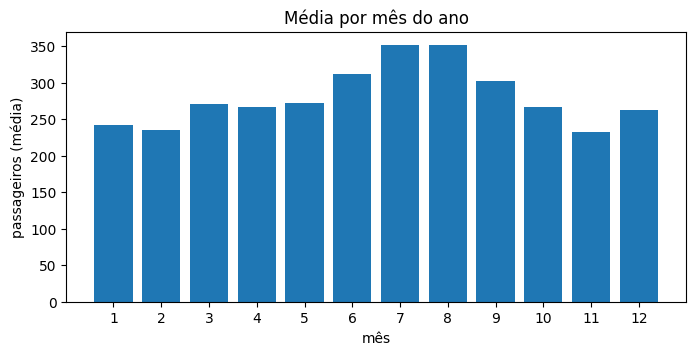

In [ ]:
plt.figure(figsize=(8, 3.5))
plt.bar(por_mes.index, por_mes.values)
plt.xticks(range(1, 13))
plt.xlabel('mês')
plt.ylabel('passageiros (média)')
plt.title('Média por mês do ano')
plt.show()

Os meses de verão (junho a setembro) têm mais passageiros, e o padrão se repete todo ano.

Para ver o padrão **ano a ano**, vamos reorganizar a série `passageiros` em uma tabela com os meses nas linhas e os anos nas colunas. Lembrando como ela está:

In [ ]:
passageiros.head()

,Passageiros
Mes,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


O `pivot_table` precisa de um `DataFrame`, e o método `.to_frame('passageiros')` transforma a `Series` em um `DataFrame` com uma coluna chamada `passageiros`:

In [ ]:
base = passageiros.to_frame('passageiros')
base.head()

,passageiros
Mes,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


O **`pivot_table`** reorganiza os dados em uma tabela de dupla entrada. Argumentos, um por linha:

In [ ]:
tabela = base.pivot_table(
    # o que vira as linhas (aqui, o mês de cada data)
    index=base.index.month,

    # o que vira as colunas (aqui, o ano de cada data)
    columns=base.index.year,

    # a coluna que preenche a tabela
    values='passageiros',

    # como juntar valores que caem na mesma célula (padrão: 'mean', a média)
    # como cada par mês-ano aparece uma vez, a média é o próprio valor
    aggfunc='mean',
)

In [ ]:
tabela.head()

Mes,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
Mes,,,,,,,,,,,,
1,112.0,115.0,145.0,171.0,196.0,204.0,242.0,284.0,315.0,340.0,360.0,417.0
2,118.0,126.0,150.0,180.0,196.0,188.0,233.0,277.0,301.0,318.0,342.0,391.0
3,132.0,141.0,178.0,193.0,236.0,235.0,267.0,317.0,356.0,362.0,406.0,419.0
4,129.0,135.0,163.0,181.0,235.0,227.0,269.0,313.0,348.0,348.0,396.0,461.0
5,121.0,125.0,172.0,183.0,229.0,234.0,270.0,318.0,355.0,363.0,420.0,472.0


In [ ]:
print('Linhas da tabela (meses):', tabela.shape[0])
print('Colunas da tabela (anos):', tabela.shape[1])

Linhas da tabela (meses): 12
Colunas da tabela (anos): 12


Plotando a tabela, cada **coluna** vira uma linha, ou seja, uma linha por ano. A barra lateral (`plt.colorbar`) mostra a escala de cores: do roxo (primeiro ano) ao amarelo (último ano):

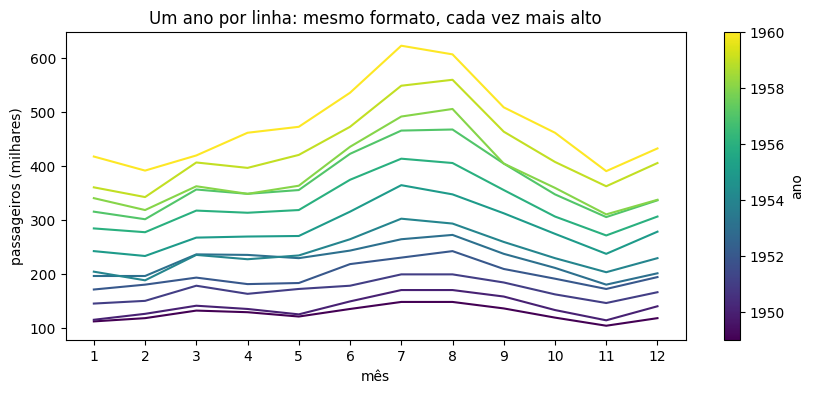

In [ ]:
ax = tabela.plot(figsize=(10, 4), legend=False, colormap='viridis')
escala = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(tabela.columns.min(), tabela.columns.max()))
plt.colorbar(escala, ax=ax, label='ano')
plt.xticks(range(1, 13))
plt.xlabel('mês')
plt.ylabel('passageiros (milhares)')
plt.title('Um ano por linha: mesmo formato, cada vez mais alto')
plt.show()

## 📌 5 - Modelo aditivo e multiplicativo

Vamos ver a diferença em um exemplo simples, construindo as duas séries com os mesmos componentes. Primeiro o eixo do tempo: 120 meses (10 anos). `np.arange(n)` cria os números 0, 1, 2, ..., n-1, e `pd.date_range` cria as datas, de mês em mês (`freq='MS'` é o início de cada mês):

In [ ]:
n = 120
t = np.arange(n)
indice = pd.date_range('2000-01-01', periods=n, freq='MS')
print('Primeiros valores de t:', [int(v) for v in t[:5]])
print('Primeiras datas:', [data.date() for data in indice[:3]])

Primeiros valores de t: [0, 1, 2, 3, 4]
Primeiras datas: [datetime.date(2000, 1, 1), datetime.date(2000, 2, 1), datetime.date(2000, 3, 1)]


A **tendência**: uma reta que sobe 2,5 por mês, começando em 100:

In [ ]:
tendencia = 100 + 2.5 * t
print('Primeiro valor:', tendencia[0])
print('Último valor:', tendencia[-1])

Primeiro valor: 100.0
Último valor: 397.5


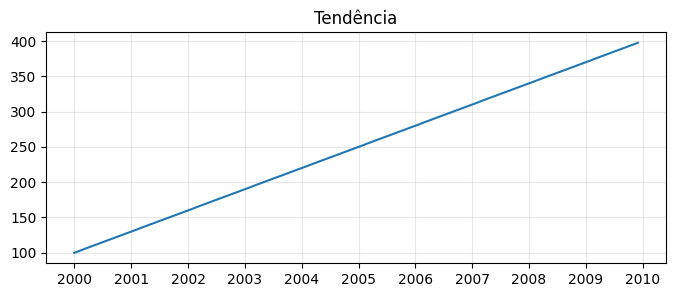

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(indice, tendencia)
plt.title('Tendência')
plt.grid(alpha=0.3)
plt.show()

A **sazonalidade**: `np.sin` gera uma onda entre -1 e 1, e `2 * np.pi * t / 12` faz um ciclo completo a cada 12 meses:

In [ ]:
sazonalidade = np.sin(2 * np.pi * t / 12)
print('Mínimo:', round(sazonalidade.min(), 2))
print('Máximo:', round(sazonalidade.max(), 2))

Mínimo: -1.0
Máximo: 1.0


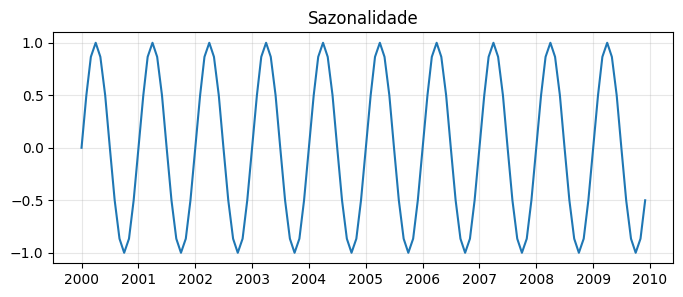

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(indice, sazonalidade)
plt.title('Sazonalidade')
plt.grid(alpha=0.3)
plt.show()

O **ruído**: variação aleatória, sem padrão, em torno do nível da série. O `rng.normal(0, 10, n)` sorteia `n` valores de uma distribuição normal com média 0 e desvio-padrão 10 (o `rng` é o mesmo gerador de números aleatórios de antes, com a mesma semente):

In [ ]:
rng = np.random.default_rng(42)
ruido = rng.normal(0, 10, n)
print('Média do ruído:', round(ruido.mean(), 2))
print('Desvio-padrão do ruído:', round(ruido.std(), 2))

Média do ruído: -0.6
Desvio-padrão do ruído: 7.82


> Os valores medidos ficam perto de 0 e 10, mas não são iguais, porque são uma amostra aleatória de 120 pontos.

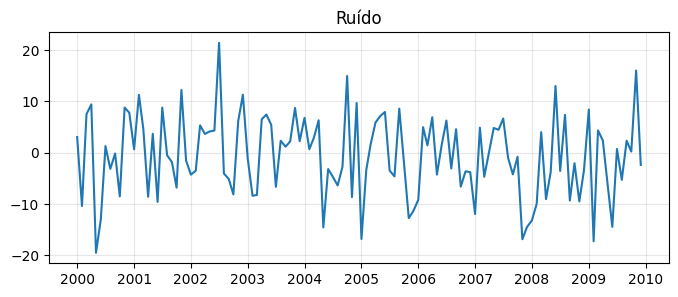

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(indice, ruido)
plt.title('Ruído')
plt.grid(alpha=0.3)
plt.show()

> Nos modelos a seguir, deixamos o ruído de fora, para a diferença entre aditivo e multiplicativo ficar clara.

### 5.1 - Modelo aditivo

No modelo **aditivo**, os componentes são somados, e a amplitude da sazonalidade é constante: $y_t = T_t + S_t + R_t$, em que $T$ é a tendência, $S$ a sazonalidade e $R$ o ruído (no nosso exemplo, sem ruído). Somamos a sazonalidade (multiplicada por 25) à tendência. A onda terá sempre a mesma altura:

In [ ]:
aditivo = tendencia + 25 * sazonalidade
print('Primeiro valor:', round(aditivo[0], 1))
print('Último valor:', round(aditivo[-1], 1))

Primeiro valor: 100.0
Último valor: 385.0


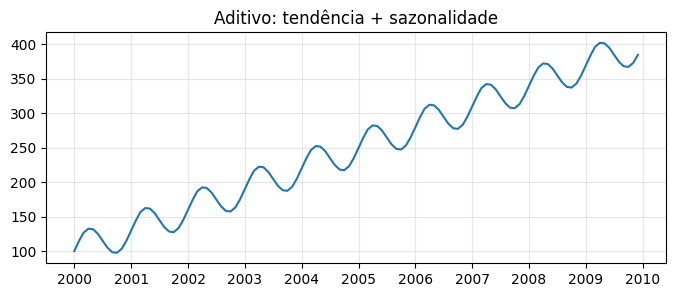

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(indice, aditivo)
plt.title('Aditivo: tendência + sazonalidade')
plt.grid(alpha=0.3)
plt.show()

### 5.2 - Modelo multiplicativo

No modelo **multiplicativo**, os componentes são multiplicados, e a amplitude cresce junto com o nível: $y_t = T_t \times S_t \times R_t$. A sazonalidade multiplica a tendência: a onda vale 25% do nível, então cresce junto com ele:

In [ ]:
multiplicativo = tendencia * (1 + 0.25 * sazonalidade)
print('Primeiro valor:', round(multiplicativo[0], 1))
print('Último valor:', round(multiplicativo[-1], 1))

Primeiro valor: 100.0
Último valor: 347.8


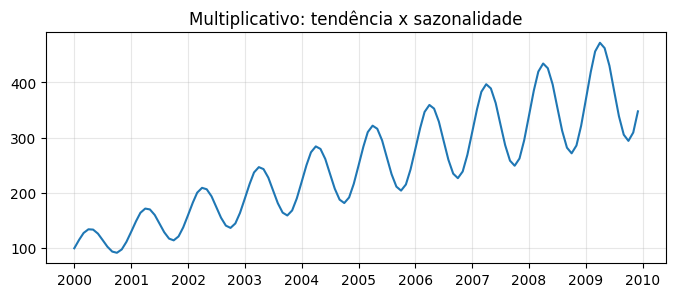

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(indice, multiplicativo)
plt.title('Multiplicativo: tendência x sazonalidade')
plt.grid(alpha=0.3)
plt.show()

Para comparar, as duas séries lado a lado:

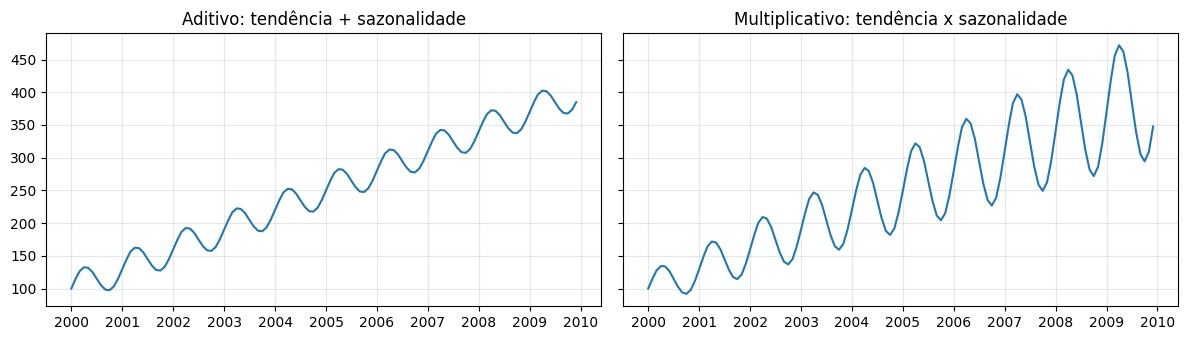

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
eixos[0].plot(indice, aditivo)
eixos[0].set_title('Aditivo: tendência + sazonalidade')
eixos[1].plot(indice, multiplicativo)
eixos[1].set_title('Multiplicativo: tendência x sazonalidade')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.3 - Método de detecção de modelo

No aditivo a onda tem sempre a mesma altura. No multiplicativo ela cresce junto com a tendência.

Vamos identificar o modelo do AirPassengers. Pelo gráfico do início, a oscilação cresce com o tempo, o que sugere multiplicativo. Para checar com números, seguimos um **método** com quatro passos. A **amplitude** de um ano é o maior valor menos o menor valor do ano.

1. **Agrupar** a série por ano
2. Calcular, em cada ano, a **média** (o nível) e a **amplitude**
3. Calcular, em cada ano, a razão **amplitude / média**
4. **Comparar:** se a amplitude cresce junto com a média (razão aproximadamente constante), o modelo é **multiplicativo**. Se a amplitude fica estável, é **aditivo**

Retomando a série `passageiros`:

In [ ]:
passageiros.head()

,Passageiros
Mes,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


**Passo 1: agrupar por ano.** Usamos o `groupby` com o ano de cada data (`.year`) como chave:

In [ ]:
grupos_ano = passageiros.groupby(passageiros.index.year)
grupos_ano

**Passo 2: média e amplitude de cada ano.** Para entender o cálculo, primeiro na mão, para 1949. O maior e o menor valor do ano, com `.max()` e `.min()`:

In [ ]:
ano_1949 = passageiros.loc['1949']
print('Maior valor de 1949:', ano_1949.max())
print('Menor valor de 1949:', ano_1949.min())

Maior valor de 1949: 148
Menor valor de 1949: 104


A amplitude é a diferença entre eles, e a média é o nível do ano:

In [ ]:
amplitude_1949 = ano_1949.max() - ano_1949.min()
print('Amplitude (maior - menor):', amplitude_1949)
print('Média de 1949:', round(ano_1949.mean(), 2))

Amplitude (maior - menor): 44
Média de 1949: 126.67


Para **todos os anos de uma vez**, usamos os mesmos métodos no grupo. O maior valor de cada ano:

In [ ]:
grupos_ano.max()

,Passageiros
Mes,
1949,148
1950,170
1951,199
1952,242
1953,272
1954,302
1955,364
1956,413
1957,467


O menor valor de cada ano:

In [ ]:
grupos_ano.min()

,Passageiros
Mes,
1949,104
1950,114
1951,145
1952,171
1953,180
1954,188
1955,233
1956,271
1957,301


Juntamos a média e a amplitude em uma tabela com `pd.DataFrame({...})`: cada chave do dicionário vira uma coluna.

In [ ]:
resumo = pd.DataFrame({
    'media': grupos_ano.mean(),
    'amplitude': grupos_ano.max() - grupos_ano.min(),
})
resumo

,media,amplitude
Mes,,
1949,126.666667,44
1950,139.666667,56
1951,170.166667,54
1952,197.000000,71
1953,225.000000,92
1954,238.916667,114
1955,284.000000,131
1956,328.250000,142
1957,368.416667,166


**Passo 3: razão amplitude / média** de cada ano. Primeiro para 1949, na mão:

In [ ]:
print('Amplitude / média de 1949:', round(amplitude_1949 / ano_1949.mean(), 2))

Amplitude / média de 1949: 0.35


E para todos os anos, dividindo as duas colunas:

In [ ]:
resumo['amplitude / media'] = resumo['amplitude'] / resumo['media']
resumo.round(2)

,media,amplitude,amplitude / media
Mes,,,
1949,126.67,44,0.35
1950,139.67,56,0.40
1951,170.17,54,0.32
1952,197.00,71,0.36
1953,225.00,92,0.41
1954,238.92,114,0.48
1955,284.00,131,0.46
1956,328.25,142,0.43
1957,368.42,166,0.45


**Passo 4: comparar.** Primeiro a amplitude e a média no primeiro e no último ano:

In [ ]:
print('Amplitude em', resumo.index[0], ':', resumo['amplitude'].iloc[0], '| em', resumo.index[-1], ':', resumo['amplitude'].iloc[-1])
print('Média em', resumo.index[0], ':', round(resumo['media'].iloc[0], 1), '| em', resumo.index[-1], ':', round(resumo['media'].iloc[-1], 1))

Amplitude em 1949 : 44 | em 1960 : 232
Média em 1949 : 126.7 | em 1960 : 476.2


E a faixa de variação da razão ao longo dos anos:

In [ ]:
print('Amplitude / média: mínimo', round(resumo['amplitude / media'].min(), 2), '| máximo', round(resumo['amplitude / media'].max(), 2))

Amplitude / média: mínimo 0.32 | máximo 0.51


A amplitude cresce junto com a média (de 44 para 232, enquanto a média vai de 127 para 476). Em um modelo aditivo a amplitude ficaria estável; aqui ela acompanha o nível. O AirPassengers apresenta, portanto, comportamento **compatível com um modelo multiplicativo**.

> A razão amplitude / média é uma **heurística**: ela indica o modelo, mas não o prova. Ela só faz sentido em séries com **zero natural** (como o número de passageiros). Em séries como a temperatura em °F ou °C, o zero é arbitrário e a razão perde o sentido.

## 🎯 Momento de praticar

Faça a mesma análise com **outra série**: a temperatura média mensal de Nottingham (1920 a 1939). O arquivo tem as colunas `Month` e `Temperature`. Os passos:

1. Carregue o dataset e plote a série
2. **Tendência:** calcule a média anual
3. **Sazonalidade:** calcule a média por mês do ano
4. Teste se a série é **aditiva** ou **multiplicativa** (amplitude e média por ano; a temperatura não tem zero natural, então compare as amplitudes, sem a razão)

Para carregar o dataset, use:

```python
df_temp = pd.read_csv(
    PATH + 'datasets/temperatura_media_mensal.csv',
    parse_dates=['Month'],
    index_col='Month',
)
temp = df_temp['Temperature']
```

**Passo 1:** carregue o dataset e plote a série.

In [ ]:
df_temp = pd.read_csv(
    PATH + 'datasets/temperatura_media_mensal.csv',
    parse_dates=['Month'],
    index_col='Month',
)
temp = df_temp['Temperature']
print('Primeira data:', temp.index.min().date())
print('Última data:', temp.index.max().date())
print('Número de linhas:', len(temp))

Primeira data: 1920-01-01
Última data: 1939-12-01
Número de linhas: 240


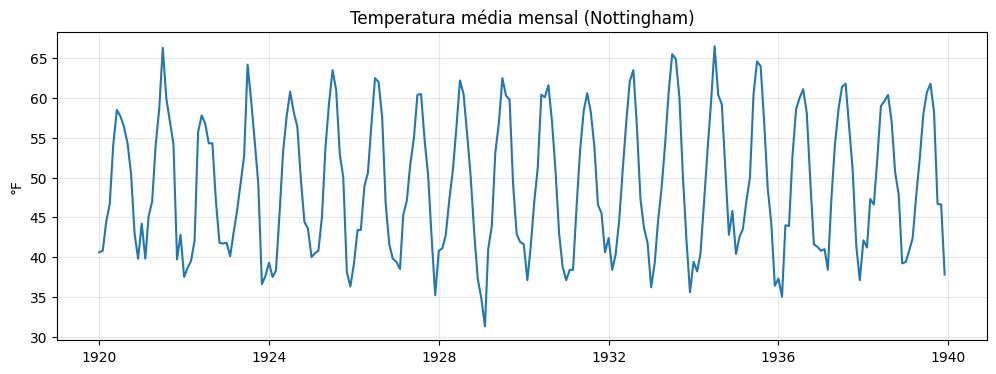

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(temp.index, temp.values)
plt.title('Temperatura média mensal (Nottingham)')
plt.ylabel('°F')
plt.grid(alpha=0.3)
plt.show()

**Passo 2, tendência:** calcule a média anual com `resample` e plote.

In [ ]:
anual_t = temp.resample('YS').mean()
anual_t.round(1).head()

,Temperature
Month,
1920-01-01,48.9
1921-01-01,50.7
1922-01-01,47.3
1923-01-01,47.8
1924-01-01,48.7


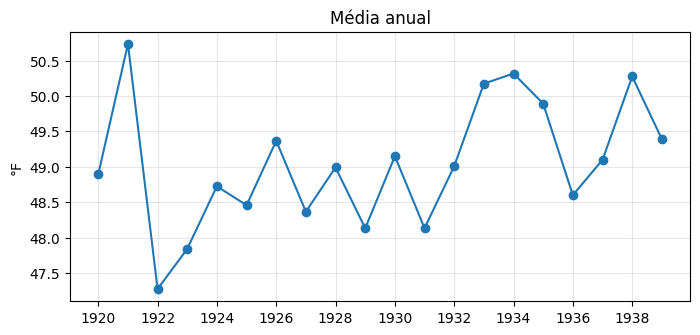

In [ ]:
plt.figure(figsize=(8, 3.5))
plt.plot(anual_t.index, anual_t.values, marker='o')
plt.title('Média anual')
plt.ylabel('°F')
plt.grid(alpha=0.3)
plt.show()

**Passo 3, sazonalidade:** calcule a média por mês do ano com `groupby` e plote.

In [ ]:
por_mes_t = temp.groupby(temp.index.month).mean()
por_mes_t.round(1)

,Temperature
Month,
1,39.7
2,39.2
3,42.2
4,46.3
5,52.6
6,58.0
7,61.9
8,60.5
9,56.5


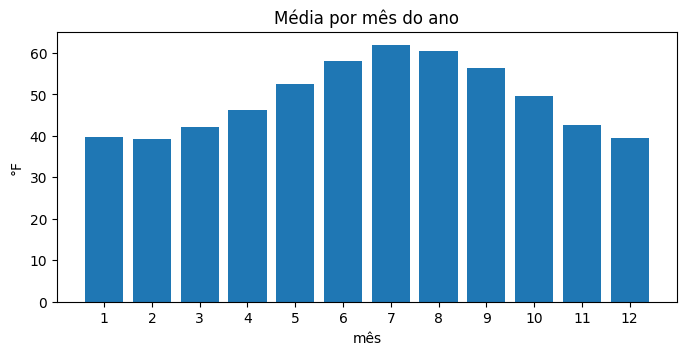

In [ ]:
plt.figure(figsize=(8, 3.5))
plt.bar(por_mes_t.index, por_mes_t.values)
plt.xticks(range(1, 13))
plt.xlabel('mês')
plt.ylabel('°F')
plt.title('Média por mês do ano')
plt.show()

**Passo 4, aditivo ou multiplicativo:** agrupe por ano, calcule a média e a amplitude (maior menos menor valor) de cada ano, e compare.

> Aqui não usamos a razão amplitude / média: a temperatura em °F não tem zero natural, então dividir pela média não faz sentido. Basta ver se a amplitude fica estável.

In [ ]:
grupos_t = temp.groupby(temp.index.year)
resumo_t = pd.DataFrame({'media': grupos_t.mean(), 'amplitude': grupos_t.max() - grupos_t.min()})
resumo_t.round(1).head()

,media,amplitude
Month,,
1920,48.9,18.7
1921,50.7,26.6
1922,47.3,20.3
1923,47.8,27.6
1924,48.7,23.3


In [ ]:
print('Amplitude anual: mínimo', round(resumo_t['amplitude'].min(), 1), '| máximo', round(resumo_t['amplitude'].max(), 1))
print('Média anual: mínimo', round(resumo_t['media'].min(), 1), '| máximo', round(resumo_t['media'].max(), 1))

Amplitude anual: mínimo 18.7 | máximo 31.2
Média anual: mínimo 47.3 | máximo 50.7


**Conclusão:**

* **Tendência:** a média anual fica entre 47,3 e 50,7 °F, sem crescer ao longo dos anos. A série não tem tendência
* **Sazonalidade:** forte e regular. O mês mais frio é fevereiro (39,2 °F) e o mais quente é julho (61,9 °F)
* **Modelo:** **aditivo**. A amplitude anual oscila entre 18,7 e 31,2 °F, sem tendência, e a média quase não muda. É o oposto do AirPassengers, em que a amplitude crescia junto com a média

## 📌 6 - Tratamento de dados

> **Dataset:** a **potência elétrica (kW)** de uma fábrica, medida a cada **15 minutos** durante 2024. Os dados são **sintéticos**, criados para esta aula com o formato de um medidor real. É um caso mais próximo do real.

Antes de qualquer análise, precisamos saber se podemos confiar nos dados.

### 6.1 - Granularidade

A **granularidade** é o intervalo entre as medições. Ela define o que conseguimos enxergar na série. Primeiro carregamos os dados, com os mesmos argumentos de antes (`parse_dates` e `index_col`). O `PATH` é o endereço base definido no Setup:

In [ ]:
df = pd.read_csv(PATH + 'datasets/consumo_energia_industrial.csv', parse_dates=['timestamp'], index_col='timestamp')
df.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,150.2
2024-01-01 00:15:00,143.3
2024-01-01 00:30:00,152.6
2024-01-01 00:45:00,153.6
2024-01-01 01:00:00,138.5


Selecionamos a coluna `potencia_kw`, que é uma `Series`:

In [ ]:
potencia = df['potencia_kw']
print('Primeiro registro:', potencia.index.min())
print('Último registro:', potencia.index.max())
print('Número de registros:', len(potencia))

Primeiro registro: 2024-01-01 00:00:00
Último registro: 2024-12-31 23:45:00
Número de registros: 34968


Para medir o intervalo entre as medições, `.to_series()` transforma o índice em uma `Series` de datas, e `.diff()` calcula a diferença de cada data para a **anterior** (a primeira não tem anterior, então vira `NaT`, "data ausente"):

In [ ]:
intervalos = potencia.index.to_series().diff()
intervalos.head()

,timestamp
timestamp,
2024-01-01 00:00:00,NaT
2024-01-01 00:15:00,0 days 00:15:00
2024-01-01 00:30:00,0 days 00:15:00
2024-01-01 00:45:00,0 days 00:15:00
2024-01-01 01:00:00,0 days 00:15:00


O método `.value_counts()` conta quantas vezes cada intervalo aparece. O esperado é 15 minutos. Qualquer outro valor indica uma **lacuna**, que veremos no próximo item:

In [ ]:
intervalos.value_counts()

,count
timestamp,
0 days 00:15:00,34965
0 days 06:15:00,1
1 days 12:15:00,1


Com medições a cada 15 minutos, um ano tem quase 35 mil pontos. Vamos ver como a granularidade muda o que enxergamos. Primeiro a série como veio, em 15 minutos:

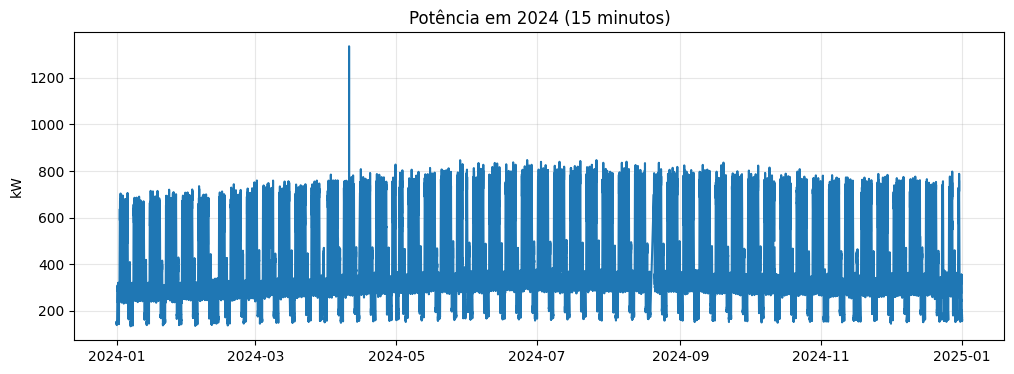

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(potencia.index, potencia.values)
plt.title('Potência em 2024 (15 minutos)')
plt.ylabel('kW')
plt.grid(alpha=0.3)
plt.show()

Uma massa densa de pontos, difícil de ler. Mudando a granularidade para **1 dia** com o `resample` (como fizemos com os anos), a média de cada dia:

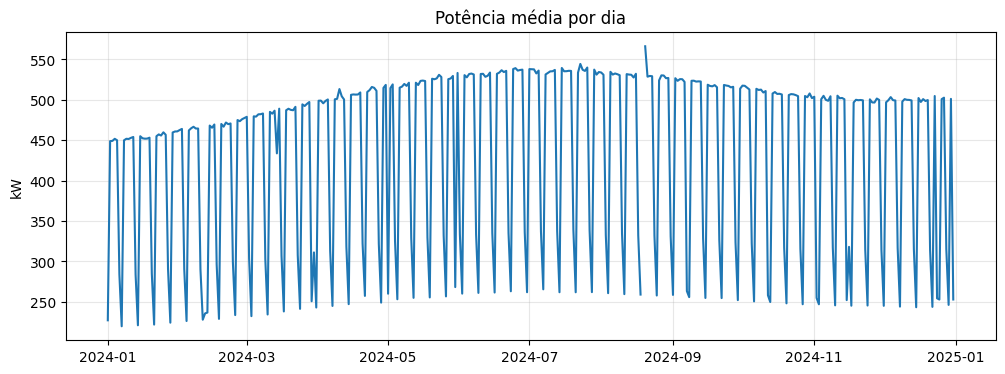

In [ ]:
diario = potencia.resample('D').mean()
plt.figure(figsize=(12, 4))
plt.plot(diario.index, diario.values)
plt.title('Potência média por dia')
plt.ylabel('kW')
plt.grid(alpha=0.3)
plt.show()

Agora aparece o padrão semanal: dias úteis altos e fins de semana baixos. Com **1 mês** (`'MS'`), a média de cada mês:

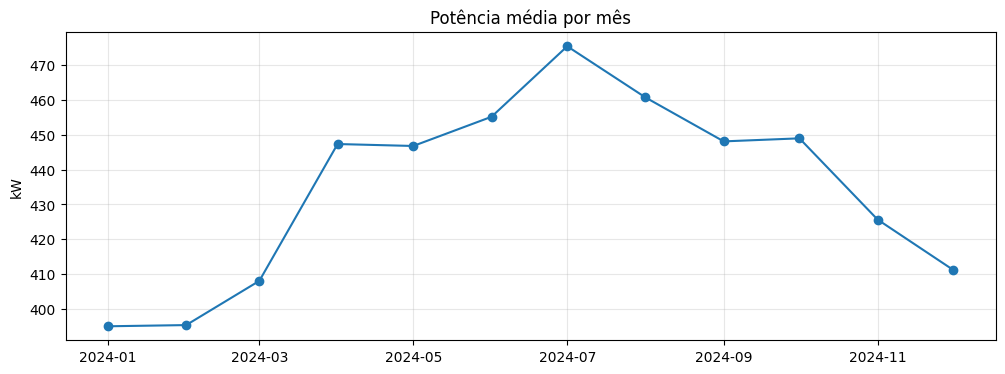

In [ ]:
mensal = potencia.resample('MS').mean()
plt.figure(figsize=(12, 4))
plt.plot(mensal.index, mensal.values, marker='o')
plt.title('Potência média por mês')
plt.ylabel('kW')
plt.grid(alpha=0.3)
plt.show()

Sobra só o nível geral do ano, mais alto no meio do ano e mais baixo no começo e no fim. E olhando **um dia** na granularidade original de 15 minutos. O `.loc['2024-03-06']` seleciona o dia inteiro, porque o índice tem precisão de minutos (a mesma regra de antes):

Pontos em um dia: 96


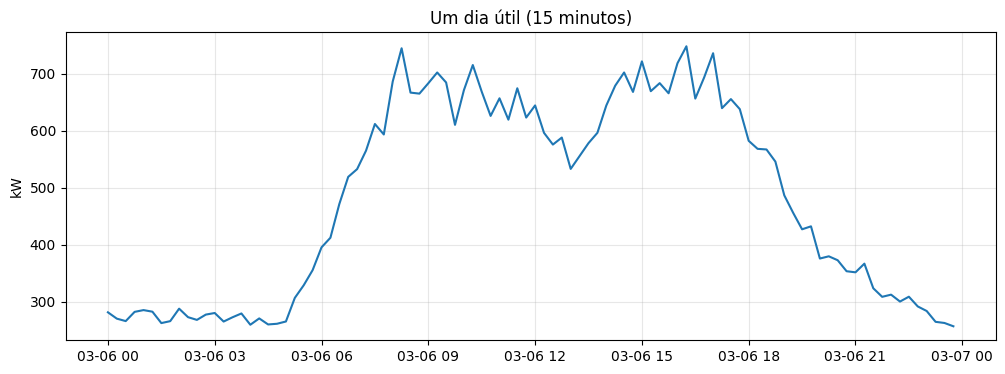

In [ ]:
um_dia = potencia.loc['2024-03-06']
print('Pontos em um dia:', len(um_dia))
plt.figure(figsize=(12, 4))
plt.plot(um_dia.index, um_dia.values)
plt.title('Um dia útil (15 minutos)')
plt.ylabel('kW')
plt.grid(alpha=0.3)
plt.show()

**Conclusão:** cada granularidade mostra alguns padrões e esconde outros.

* **15 minutos, no ano todo:** muitos pontos, nenhum padrão fica claro
* **1 dia:** aparece o padrão semanal (dias úteis altos e fins de semana baixos)
* **1 mês:** aparece só o nível geral do ano
* **15 minutos, em um dia:** aparece o ciclo diário (o consumo sobe de manhã e cai à noite)

Escolhemos a granularidade de acordo com o que queremos analisar.

### 6.2 - Lacunas no tempo

Uma **lacuna** é um intervalo em que nem a linha existe (diferente de uma célula vazia). O `asfreq` reconstrói a série em uma **grade regular**, com uma linha para cada instante na frequência pedida. Onde a linha não existia, ela é criada com `NaN` (valor ausente). O argumento `'15min'` é a frequência: 15 minutos.

In [ ]:
completo = potencia.asfreq('15min')
print('Linhas na grade completa:', len(completo))
print('Linhas existentes:', len(potencia))

Linhas na grade completa: 35136
Linhas existentes: 34968


> Outros códigos de frequência: `'h'` para hora e `'D'` para dia.

O método `.index.difference(outro)` devolve os rótulos que estão no primeiro índice e **não** estão no segundo. Aqui, os timestamps da grade completa que não existiam na série:

In [ ]:
sem_registro = completo.index.difference(potencia.index)
print('Timestamps sem registro:', len(sem_registro))

Timestamps sem registro: 168


Agora precisamos **agrupar os faltantes consecutivos**, para listar cada lacuna. Para isso usamos um truque em três passos, primeiro em um exemplo pequeno: números que faltam em uma grade, onde o esperado é diferença de 1 entre um valor e o próximo.

In [ ]:
exemplo = pd.Series([1, 2, 3, 7, 8, 12])
exemplo

,0
0,1
1,2
2,3
3,7
4,8
5,12


`.diff()`, a diferença para o anterior:

In [ ]:
exemplo.diff()

,0
0,NaN
1,1.0
2,1.0
3,4.0
4,1.0
5,4.0


Comparando com 1: `True` onde **começa um bloco novo**:

In [ ]:
exemplo.diff() != 1

,0
0,True
1,False
2,False
3,True
4,False
5,True


E `.cumsum()` (soma acumulada) numera os blocos, porque cada `True` soma 1:

In [ ]:
(exemplo.diff() != 1).cumsum()

,0
0,1
1,1
2,1
3,2
4,2
5,3


Os valores 1, 2, 3 ficam no bloco 1, os valores 7, 8 no bloco 2 e o 12 no bloco 3. Aplicamos o mesmo aos timestamps faltantes, com `pd.Timedelta('15min')` (a duração de 15 minutos) no lugar do 1:

In [ ]:
faltantes = pd.Series(sem_registro)
novo_bloco = faltantes.diff() != pd.Timedelta('15min')
grupos = novo_bloco.cumsum()
pd.DataFrame({'faltante': faltantes, 'novo_bloco': novo_bloco, 'grupo': grupos}).head(8)

,faltante,novo_bloco,grupo
0,2024-03-14 08:00:00,True,1
1,2024-03-14 08:15:00,False,1
2,2024-03-14 08:30:00,False,1
3,2024-03-14 08:45:00,False,1
4,2024-03-14 09:00:00,False,1
5,2024-03-14 09:15:00,False,1
6,2024-03-14 09:30:00,False,1
7,2024-03-14 09:45:00,False,1


Com o número do grupo, `.groupby(grupos).agg(...)` resume cada lacuna. Em `agg`, cada argumento é `nome_da_coluna='função'`: `'min'` é o primeiro timestamp, `'max'` o último e `'count'` a quantidade:

In [ ]:
lacunas = faltantes.groupby(grupos).agg(inicio='min', fim='max', quantidade='count')
lacunas['duracao'] = lacunas['quantidade'] * pd.Timedelta('15min')
lacunas

,inicio,fim,quantidade,duracao
timestamp,,,,
1,2024-03-14 08:00:00,2024-03-14 13:45:00,24,0 days 06:00:00
2,2024-08-19 00:00:00,2024-08-20 11:45:00,144,1 days 12:00:00


In [ ]:
print('Número de lacunas:', len(lacunas))
print('Maior lacuna:', lacunas['duracao'].max())

Número de lacunas: 2
Maior lacuna: 1 days 12:00:00


Para ver as lacunas, plotamos a grade completa (`completo`) em uma janela de 1 dia antes e 1 dia depois de cada uma. Onde há `NaN` a linha é interrompida, e a faixa vermelha (`axvspan`) marca o intervalo da lacuna:

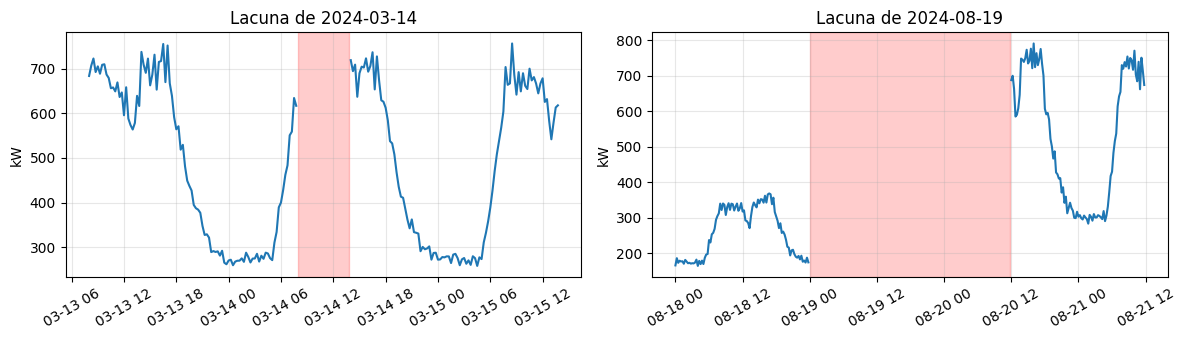

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
for eixo, inicio, fim in zip(eixos, lacunas['inicio'], lacunas['fim']):
    janela = completo.loc[inicio - pd.Timedelta('1D'):fim + pd.Timedelta('1D')]
    eixo.plot(janela.index, janela.values)
    eixo.axvspan(inicio, fim, color='red', alpha=0.2)
    eixo.set_title('Lacuna de ' + str(inicio.date()))
    eixo.set_ylabel('kW')
    eixo.tick_params(axis='x', rotation=30)
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.3 - Picos isolados

O **z-score** diz **quantos desvios-padrão** um valor está acima (ou abaixo) da média:

$$z = \frac{x - \mu}{\sigma}$$

Um `z > 4` é muito raro: indica um pico anormal.

> O **4** é um valor arbitrário: definimos como 4 vezes o desvio-padrão. É um desvio muito grande, mas poderia ser 3 ou outro valor.

Primeiro calculamos o z com a média e o desvio-padrão da **série inteira** (z global):

In [ ]:
z_global = (potencia - potencia.mean()) / potencia.std()
print('Média da série:', round(potencia.mean(), 1))
print('Desvio-padrão da série:', round(potencia.std(), 1))
print('Picos encontrados (z global > 4):', int((z_global > 4).sum()))

Média da série: 434.8
Desvio-padrão da série: 191.3
Picos encontrados (z global > 4): 1


In [ ]:
potencia[z_global > 4]

,potencia_kw
timestamp,
2024-04-10 14:30:00,1335.6


O z global acha só 1 pico. Mas o consumo muda muito ao longo do dia: fica perto de 250 kW na madrugada e perto de 600 kW durante o dia. Um valor alto para a madrugada pode ser comum para a série inteira, e o z global deixa passar esses picos.

Por isso comparamos cada medida só com as **medidas da mesma hora**: a mesma conta do z, mas com a média e o desvio-padrão do **grupo** da hora.

Para agrupar por hora, usamos o atributo `.hour` do índice: a hora de cada data (de 0 a 23):

In [ ]:
print('Hora das 5 primeiras linhas:', list(potencia.index.hour[:5]))

Hora das 5 primeiras linhas: [0, 0, 0, 0, 1]


Passamos essa hora direto para o `groupby`: cada hora do dia é um grupo, ou seja, 24 grupos:

In [ ]:
print('Número de grupos:', potencia.groupby(potencia.index.hour).ngroups)

Número de grupos: 24


Cada grupo reúne as medidas daquela hora, de **todos os dias do ano**. Por exemplo, o grupo das 8h tem as medidas de 8:00, 8:15, 8:30 e 8:45 de cada dia. Selecionando esse grupo na mão:

In [ ]:
hora_8 = potencia[potencia.index.hour == 8]
print('Medidas no grupo das 8h:', len(hora_8))
print('Média do grupo:', round(hora_8.mean(), 2))

Medidas no grupo das 8h: 1452
Média do grupo: 600.94


In [ ]:
hora_8.head(8)

,potencia_kw
timestamp,
2024-01-01 08:00:00,294.1
2024-01-01 08:15:00,290.2
2024-01-01 08:30:00,304.4
2024-01-01 08:45:00,309.0
2024-01-02 08:00:00,616.3
2024-01-02 08:15:00,608.2
2024-01-02 08:30:00,618.2
2024-01-02 08:45:00,594.8


Com `.mean()` no grupo, calculamos a média de **cada uma das 24 horas** de uma vez. O resultado tem uma linha por grupo, com a hora no índice:

In [ ]:
media_hora = potencia.groupby(potencia.index.hour).mean()
media_hora.head(6)

,potencia_kw
timestamp,
0,252.001992
1,251.608723
2,251.442612
3,252.258144
4,251.343819
5,291.776648


In [ ]:
print('Linhas da tabela de médias:', len(media_hora))
print('Média do grupo das 8h:', round(media_hora.loc[8], 2))

Linhas da tabela de médias: 24
Média do grupo das 8h: 600.94


Para o z-score, precisamos da média da hora **ao lado de cada medida**, mas essa tabela tem só 24 linhas (a série tem quase 35 mil). O `.transform('mean')` faz o mesmo cálculo, mas **repete a média do grupo em cada linha** do grupo. A `Series` volta com o mesmo tamanho e o mesmo índice da original, então a conta pode ser feita linha a linha:

In [ ]:
media_ref = potencia.groupby(potencia.index.hour).transform('mean')
media_ref.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,252.001992
2024-01-01 00:15:00,252.001992
2024-01-01 00:30:00,252.001992
2024-01-01 00:45:00,252.001992
2024-01-01 01:00:00,251.608723


As 4 primeiras linhas (00:00 a 00:45) são do grupo da hora 0, por isso têm a mesma média. A linha das 01:00 já é do grupo da hora 1, com outra média.

O mesmo para o desvio-padrão (`'std'`):

In [ ]:
desvio_ref = potencia.groupby(potencia.index.hour).transform('std')
desvio_ref.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,52.629773
2024-01-01 00:15:00,52.629773
2024-01-01 00:30:00,52.629773
2024-01-01 00:45:00,52.629773
2024-01-01 01:00:00,53.032484


Com os dois, calculamos o z-score de cada medida:

In [ ]:
z = (potencia - media_ref) / desvio_ref
z.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,-1.934304
2024-01-01 00:15:00,-2.065409
2024-01-01 00:30:00,-1.888703
2024-01-01 00:45:00,-1.869702
2024-01-01 01:00:00,-2.132820


In [ ]:
tabela_z = pd.DataFrame({'valor': potencia, 'media_ref': media_ref, 'desvio_ref': desvio_ref, 'z': z})
picos = tabela_z[z > 4]
print('Medidas analisadas:', len(potencia))
print('Picos encontrados (z > 4):', len(picos))

Medidas analisadas: 34968
Picos encontrados (z > 4): 3


In [ ]:
picos.round(2)

,valor,media_ref,desvio_ref,z
timestamp,,,,
2024-04-10 14:30:00,1335.6,608.29,165.55,4.39
2024-07-23 03:15:00,775.8,252.26,54.93,9.53
2024-10-02 21:00:00,679.5,304.29,70.83,5.30


Com o z por hora, são **3 picos**. Comparando com o z global nesses mesmos 3 momentos:

In [ ]:
comparacao = pd.DataFrame({'valor': picos['valor'], 'z global': z_global[picos.index], 'z por hora': picos['z']})
comparacao.round(2)

,valor,z global,z por hora
timestamp,,,
2024-04-10 14:30:00,1335.6,4.71,4.39
2024-07-23 03:15:00,775.8,1.78,9.53
2024-10-02 21:00:00,679.5,1.28,5.30


O z global só passa de 4 no maior pico. Os outros dois são altos **para o horário deles** (por exemplo, 775,8 kW às 3h15, quando a média das 3h é 252 kW), mas normais para a série inteira. Só o z por hora os encontra.

Para ver os picos, fazemos **um recorte (`slice`) por pico**: 2 dias antes e 2 dias depois de cada um, com a medida de `z > 4` em vermelho. O `pd.Timedelta('2D')` é uma duração de 2 dias:

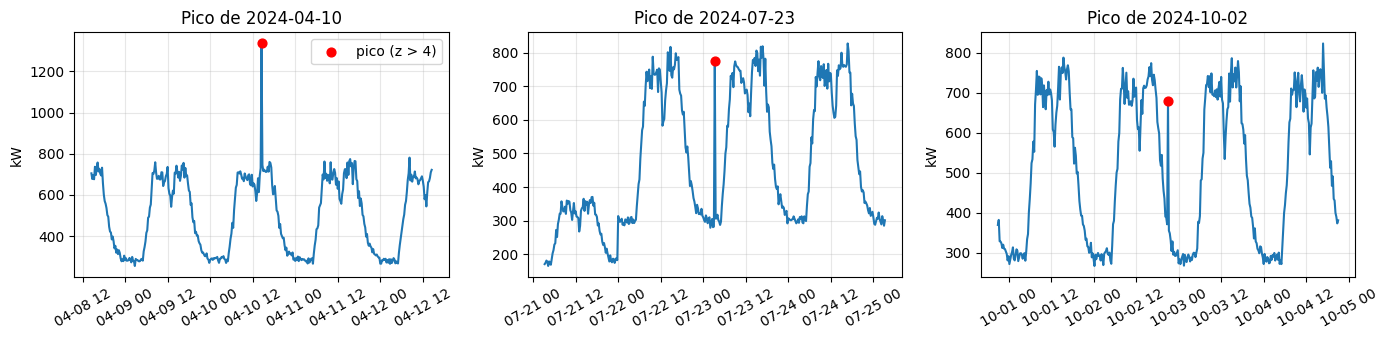

In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.5))
for eixo, instante in zip(eixos, picos.index):
    janela = slice(instante - pd.Timedelta('2D'), instante + pd.Timedelta('2D'))
    eixo.plot(potencia.loc[janela].index, potencia.loc[janela].values)
    eixo.scatter(instante, picos.loc[instante, 'valor'], color='red', s=40, zorder=3, label='pico (z > 4)')
    eixo.set_title('Pico de ' + str(instante.date()))
    eixo.set_ylabel('kW')
    eixo.tick_params(axis='x', rotation=30)
    eixo.grid(alpha=0.3)
eixos[0].legend()
plt.tight_layout()
plt.show()

### 6.4 - Interpolação dos buracos curtos

Nem todo problema deve ser "corrigido": interpolar uma lacuna de um dia inventa dados.

Vamos marcar os picos como ausentes e preencher por interpolação **só os buracos de até 2 horas** (8 medições).

Passo 1: marcar como `NaN` o que é inválido, usando o z-score `z` (dos picos), calculado na seção anterior. `.copy()` cria uma cópia (para não alterar a série original), e `limpa[condição] = np.nan` coloca `NaN` onde a condição é `True`:

In [ ]:
limpa = potencia.copy()
limpa[z > 4] = np.nan
print('Medidas marcadas como pico:', int((z > 4).sum()))
print('Ausentes (NaN) agora:', int(limpa.isna().sum()))

Medidas marcadas como pico: 3
Ausentes (NaN) agora: 17


Passo 2: recriar a grade completa de 15 minutos com `asfreq`, para que as lacunas também apareçam como `NaN`:

In [ ]:
limpa = limpa.asfreq('15min')
print('Linhas agora:', len(limpa))
print('Ausentes (NaN) agora:', int(limpa.isna().sum()))

Linhas agora: 35136
Ausentes (NaN) agora: 185


Passo 3: medir o tamanho de cada buraco (sequência de `NaN`), com o mesmo truque do `cumsum`. `.isna()` marca `True` nos `NaN`:

In [ ]:
ausente = limpa.isna()
ausente.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,False
2024-01-01 00:15:00,False
2024-01-01 00:30:00,False
2024-01-01 00:45:00,False
2024-01-01 01:00:00,False


Cada valor presente (`~ausente`) abre um grupo novo pelo `cumsum`, e os `NaN` seguintes ficam nesse mesmo grupo. Somar os `NaN` do grupo (`transform('sum')`) dá o tamanho do buraco:

In [ ]:
tamanho_buraco = ausente.groupby((~ausente).cumsum()).transform('sum')
print('Maior buraco:', int(tamanho_buraco.max()), 'medições')
print('Ausentes em buracos de até 8 medições:', int((ausente & (tamanho_buraco <= 8)).sum()))
print('Ausentes em buracos maiores que 8 medições:', int((ausente & (tamanho_buraco > 8)).sum()))

Maior buraco: 144 medições
Ausentes em buracos de até 8 medições: 17
Ausentes em buracos maiores que 8 medições: 168


Passo 4: `.interpolate()` preenche cada `NaN` com uma reta entre o valor anterior e o próximo:

In [ ]:
interpolada = limpa.interpolate()
print('Ausentes (NaN) depois de interpolar tudo:', int(interpolada.isna().sum()))

Ausentes (NaN) depois de interpolar tudo: 0


Mas não queremos preencher os buracos grandes. O `.mask(condição)` volta a colocar `NaN` onde a condição é `True`: nos buracos **maiores** que 8 medições.

In [ ]:
limpa = interpolada.mask(ausente & (tamanho_buraco > 8))
print('Ausentes (NaN) depois do tratamento:', int(limpa.isna().sum()))

Ausentes (NaN) depois do tratamento: 168


Para ver o efeito, primeiro os **picos**: 3 horas antes e 3 horas depois de cada um. A linha vermelha tracejada é a série original e a azul é a tratada, com o pico substituído por uma reta entre os vizinhos:

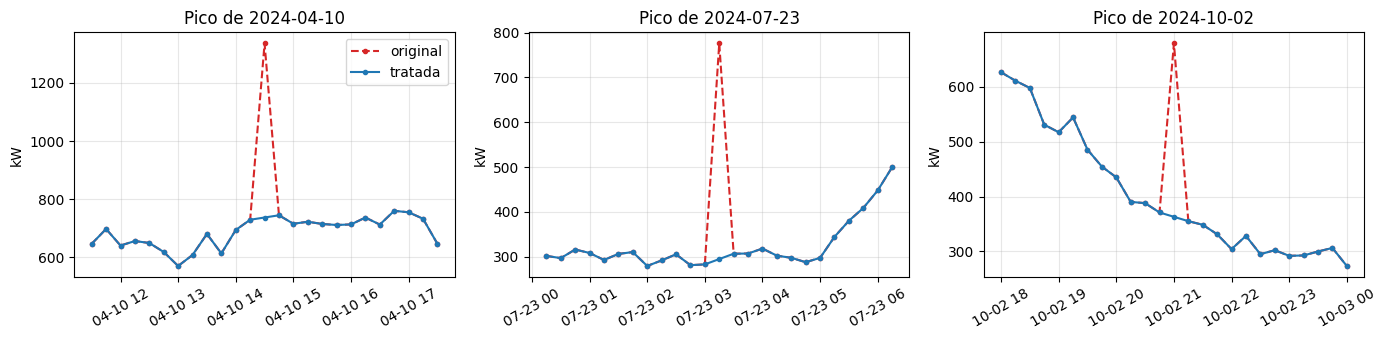

In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.5))
for eixo, instante in zip(eixos, picos.index):
    janela = slice(instante - pd.Timedelta('3h'), instante + pd.Timedelta('3h'))
    eixo.plot(potencia.loc[janela].index, potencia.loc[janela].values, color='tab:red', linestyle='--', marker='o', markersize=3, label='original')
    eixo.plot(limpa.loc[janela].index, limpa.loc[janela].values, color='tab:blue', marker='o', markersize=3, label='tratada')
    eixo.set_title('Pico de ' + str(instante.date()))
    eixo.set_ylabel('kW')
    eixo.tick_params(axis='x', rotation=30)
    eixo.grid(alpha=0.3)
eixos[0].legend()
plt.tight_layout()
plt.show()

Agora as **lacunas** do 6.2, que são buracos longos (mais de 8 medições). Na série tratada elas continuam ausentes: a linha azul é interrompida na faixa vermelha, e nada foi inventado ali:

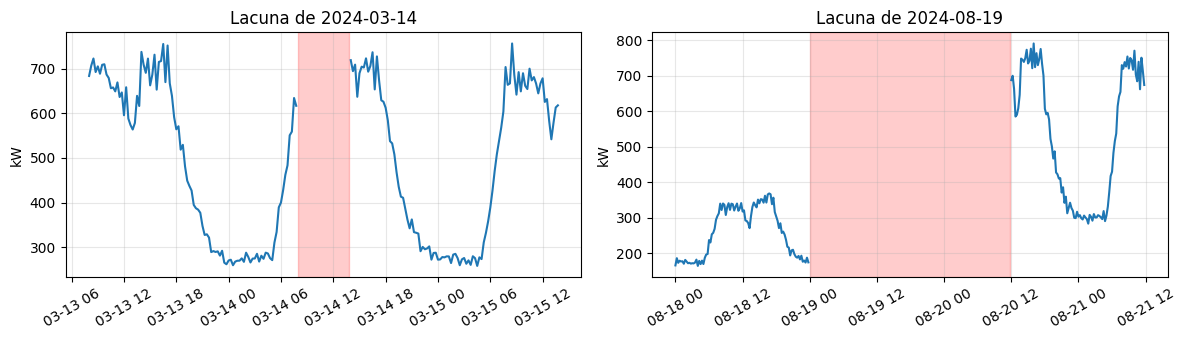

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
for eixo, inicio, fim in zip(eixos, lacunas['inicio'], lacunas['fim']):
    janela = slice(inicio - pd.Timedelta('1D'), fim + pd.Timedelta('1D'))
    eixo.plot(limpa.loc[janela].index, limpa.loc[janela].values, color='tab:blue')
    eixo.axvspan(inicio, fim, color='red', alpha=0.2)
    eixo.set_title('Lacuna de ' + str(inicio.date()))
    eixo.set_ylabel('kW')
    eixo.tick_params(axis='x', rotation=30)
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Os valores que continuam ausentes são as lacunas longas, que **não** devem ser preenchidos sem critério.

## 🎯 Momento de praticar

Repita a verificação de qualidade na **planta B**, outra fábrica, com medições **de hora em hora**. O arquivo `datasets/consumo_energia_planta_b.csv` tem as colunas `timestamp` e `potencia_kw`. Os passos:

1. Carregue o dataset e confira a frequência
2. Remova os timestamps **repetidos** (a planta A não tinha)
3. Liste as **lacunas**
4. Encontre os **picos isolados**
5. **Trate** os problemas, preenchendo só buracos de até 2 horas

Para carregar o dataset, use:

```python
df_b = pd.read_csv(
    PATH + 'datasets/consumo_energia_planta_b.csv',
    parse_dates=['timestamp'],
    index_col='timestamp',
)
pot_b = df_b['potencia_kw']
```

**Passo 1:** carregue o dataset e confira a frequência (o intervalo entre as medições).

In [ ]:
df_b = pd.read_csv(
    PATH + 'datasets/consumo_energia_planta_b.csv',
    parse_dates=['timestamp'],
    index_col='timestamp',
)
pot_b = df_b['potencia_kw']
print('Número de registros:', len(pot_b))
print('Primeiro registro:', pot_b.index.min())
print('Último registro:', pot_b.index.max())

Número de registros: 8724
Primeiro registro: 2024-01-01 00:00:00
Último registro: 2024-12-31 23:00:00


In [ ]:
pot_b.index.to_series().diff().value_counts().head()

,count
timestamp,
0 days 01:00:00,8710
0 days 00:00:00,12
3 days 01:00:00,1


**Passo 2:** remova os timestamps repetidos. O `asfreq` exige índice único, e duplicatas podem ter valores **diferentes** para o mesmo instante. Mantenha a primeira ocorrência: `.duplicated(keep='first')` marca `True` nos timestamps que já apareceram antes, e o `~` inverte a marcação para manter só as primeiras.

In [ ]:
pot_b = pot_b[~pot_b.index.duplicated(keep='first')]
print('Registros depois de remover duplicatas:', len(pot_b))

Registros depois de remover duplicatas: 8712


**Passo 3:** liste as lacunas (grade completa com `asfreq`, timestamps faltantes e agrupamento dos consecutivos).

In [ ]:
completo_b = pot_b.asfreq('h')
faltantes_b = pd.Series(completo_b.index.difference(pot_b.index))
grupos_b = (faltantes_b.diff() != pd.Timedelta('1h')).cumsum()
lacunas_b = faltantes_b.groupby(grupos_b).agg(inicio='min', fim='max', quantidade='count')
print('Timestamps sem registro:', len(faltantes_b))
print('Número de lacunas:', len(lacunas_b))

Timestamps sem registro: 72
Número de lacunas: 1


In [ ]:
lacunas_b

,inicio,fim,quantidade
timestamp,,,
1,2024-04-08,2024-04-10 23:00:00,72


**Passo 4:** encontre os picos isolados (z-score em relação à mesma hora; pico é `z > 4`).

In [ ]:
z_b = (pot_b - pot_b.groupby(pot_b.index.hour).transform('mean')) / pot_b.groupby(pot_b.index.hour).transform('std')
print('Picos encontrados (z > 4):', int((z_b > 4).sum()))

Picos encontrados (z > 4): 1


In [ ]:
pot_b[z_b > 4]

,potencia_kw
timestamp,
2024-02-21 11:00:00,3518.9


**Passo 5:** trate os problemas. Marque os picos como ausentes, recrie a grade com `asfreq`, meça o tamanho dos buracos e interpole só os de até 2 horas.

In [ ]:
limpa_b = pot_b.copy()
limpa_b[z_b > 4] = np.nan
limpa_b = limpa_b.asfreq('h')
ausente_b = limpa_b.isna()
buraco_b = ausente_b.groupby((~ausente_b).cumsum()).transform('sum')
print('Ausentes antes de interpolar:', int(ausente_b.sum()))

Ausentes antes de interpolar: 92


In [ ]:
limpa_b = limpa_b.interpolate().mask(ausente_b & (buraco_b > 2))
print('Ausentes depois de interpolar:', int(limpa_b.isna().sum()))

Ausentes depois de interpolar: 72


**Conclusão:** a planta B tinha três problemas, tratados de formas diferentes:

* **Timestamps repetidos:** 12, removidos (mantivemos a primeira ocorrência)
* **Lacuna:** uma, de 72 horas (de 08/04 a 10/04), longa demais para interpolar. Continua ausente
* **Picos:** 1 medida com z > 4 (21/02, às 11h), marcada como ausente e preenchida por interpolação (buraco curto)

Os buracos curtos foram preenchidos (de 92 ausentes para 72): o pico e os 19 valores que já vinham vazios no arquivo. Os 72 que restam são a lacuna de 72 horas.

## 📌 Conclusão

* Uma série temporal tem **índice de tempo**, e a **ordem** carrega informação: o valor de agora depende do passado
* Série real tem **frequência**, **lacunas** e **picos**: verificamos antes de analisar
* Nem todo problema deve ser corrigido: interpolamos só buracos curtos
* Tendência, sazonalidade e **ruído** são os componentes da série, e o modelo **aditivo** ou **multiplicativo** descreve como eles se combinam
* Esses dados tratados são a base para os modelos de previsão das próximas aulas